# 03 · 1D Fourier 神经算子解热方程（中级）

**前置：** 02；了解 sin/cos。**目标：** 从零实现 Fourier 层，在 64 点训练并在 128 点推理。

解 $u_t=\nu u_{xx}$，$x\in[0,1)$，周期边界，$\nu=0.01$，终止时间 $T=0.2$。算子映射 $u_0(\cdot)\mapsto u(\cdot,T)$。**本章只学固定 $\nu,T$，不预测完整时空轨迹。** 对频率 $k$，解析解衰减系数为 $e^{-\nu(2\pi k)^2T}$。

参考：[FNO 原始论文](https://arxiv.org/abs/2010.08895)、[PyTorch FFT 文档](https://docs.pytorch.org/docs/stable/fft.html)。

## 原理详解 A：热方程为什么在 Fourier 空间变成独立 ODE？

周期函数可以展开成
$$
u(x,t)=\sum_{k\in\mathbb Z}\widehat u_k(t)e^{i2\pi kx}.
$$
因为 $\partial_{xx}e^{i2\pi kx}=-(2\pi k)^2e^{i2\pi kx}$，代入 $u_t=\nu u_{xx}$ 得到
$$
\frac{d\widehat u_k}{dt}=-\nu(2\pi k)^2\widehat u_k,\qquad
\widehat u_k(T)=e^{-\nu(2\pi k)^2T}\widehat u_k(0).
$$
所以本章参考解只需给每个模式乘衰减因子。$k=0$ 因子为 1，均值不变；高频因 $k^2$ 衰减更快，解变得更平滑。

这是一种“谱乘子”算子。本章 FNO 也在频谱中做乘法，但它学习的是多通道复数权重，并有局部混合与非线性层；它没有直接把上面的解析衰减公式写入网络。

参考解和网络目标只对应固定 $\nu,T$。如果不把参数加入输入，同一初值只能得到同一个输出，网络在逻辑上就无法表示多个扩散率或多个查询时间。08 章将补上这个条件输入。

周期网格 $x_j=j/N$ 不包含重复的 $x=1$。同一个端点被重复采样，会改变 FFT 所理解的等间距周期信号，不能仅把这当成绘图上的小差别。

## 原理详解 B：从积分算子到 Fourier 层

### B.1 一般算子层与卷积型特例

一种神经算子层可写为
$$
v_{\ell+1}(x)=\sigma\!\left(W_\ell v_\ell(x)+
\int_\Omega K_\ell(x,y)v_\ell(y)\,dy\right).
$$
$W_\ell$ 在每个位置混合通道，积分项传播远处的信息。若核具有平移不变形式 $K(x,y)=\kappa(x-y)$，积分就是卷积，由卷积定理得到
$$
\mathcal K v=\mathcal F^{-1}\!\left[\widehat\kappa(k)\widehat v(k)\right].
$$
FNO 的核心做法是在保留的频率上直接参数化这个频谱乘子。位置特征、局部分支和非线性组合可以使整个网络表达更丰富的映射，不能把整个网络简单等同于一个线性平移不变卷积。

### B.2 频率上的通道矩阵

对于某个频率 k，
$$
\widehat w_o(k)=\sum_{i=1}^{C_{\rm in}}R_{i,o,k}\widehat v_i(k).
$$
这就是代码中的复数 einsum。R 的每个频率都有一组输入—输出通道矩阵，不是在物理网格上给每个位置一个独立参数。复数权重可同时调节幅度与相位。

本章一层实际执行
$$
v_{\ell+1}=\operatorname{GELU}\big(\mathcal K_\ell v_\ell+W_\ell v_\ell\big).
$$
1×1 卷积只在同一位置混合通道，不直接扩展空间感受野；频谱分支提供全局联系。频谱分支截断高频，不表示整个网络最终一定带限，因为局部分支能传递高频，激活也能产生新频率。

### B.3 Lifting 与 projection

先把 $[u_0,\sin(2\pi x),\cos(2\pi x)]$ 提升到 width 个潜在通道，再经过多个算子层，最后投影成一个标量场。width 表示每个位置的特征数，modes 表示频谱分支保留的频率数量；它们控制不同能力，不可互换理解。

来源：[FNO 原论文](https://arxiv.org/abs/2010.08895)。

## 原理详解 C：FFT 归一化、实数信号与跨网格含义

PyTorch 默认 forward FFT 不除以 N，inverse FFT 除以 N。因此一对默认设置的变换能恢复原信号。若用它们实现微分或谱乘子，只要前后约定一致，不需要额外乘 N。改变 norm 设置时也必须前后匹配。

实数信号满足共轭对称 $\widehat v(-k)=\overline{\widehat v(k)}$，rFFT 只储存 $k=0,\ldots,\lfloor N/2\rfloor$，输出形状为 $[B,C,\lfloor N/2\rfloor+1]$。零频和偶数网格的 Nyquist 频率有特殊实数约束；iRFFT 返回实场时会处理这些约束。本章学习权重是复数张量，这不表示最终解是复数。

只给 iRFFT 一个压缩频谱，不能总是区分原长度是奇数还是偶数。代码显式传入 n，防止 65 点网格被重建成 64 点。见 [PyTorch FFT 文档](https://docs.pytorch.org/docs/stable/fft.html)。

在同一物理区域上，从 64 点变到 128 点，低频索引 k 仍表示同一物理波数 $2\pi k$，所以同一 R 可以复用。若区域长度改成 L，则波数应为 $2\pi k/L$；网格长度可变不代表物理区域可以不加说明地改变。

跨网格成功还依赖输入采样能分辨相关频率、训练函数分布和离散变换误差。参数尺寸不随 N 改变，只解决了“可以执行”这一层；“执行得准确”仍需同一连续测试函数在各网格上的参考解。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 周期网格不重复右端点

用 $x_j=j/N$，不要用含两个端点的 linspace 做周期 FFT。训练集、验证集和测试集各自拥有独立系数。周期数据生成器将系数除以 $k^2$，控制高频幅度。

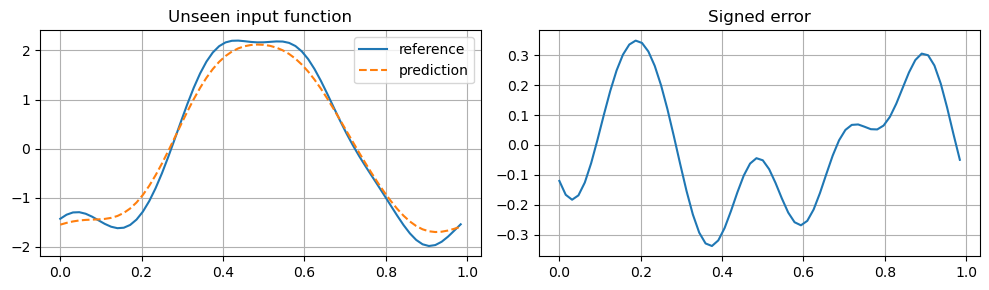

initial -> final: torch.Size([256, 64]) torch.Size([256, 64])


In [2]:
ntrain,ntest = counts()
x = torch.arange(64)/64
atrain,aval,atest = torch.randn(ntrain,10),torch.randn(ntest,10),torch.randn(ntest,10)
u0,ut = heat_data(atrain,x)
v0,vt = heat_data(aval,x)
t0,tt = heat_data(atest,x)
plot_1d(x,t0,tt)
print("initial -> final:",u0.shape,ut.shape)

## 2. Fourier 层的三个动作

$\mathcal F^{-1}(R_k\mathcal F(v)_k)$：① rFFT 得到复频谱；② 只在保留的低频上学习通道间复数矩阵；③ iFFT 回到实数网格。`einsum('bim,iom->bom')` 的 i/o 是输入/输出通道，m 是频率。点态 1×1 卷积保留局部通道混合，GELU 引入非线性。

截断频率没有直接参与频谱分支，但点态分支和激活仍可传递或生成高频。不同于给 64 个位置分别分配权重，$R_k$ 不依赖网格长度。

In [3]:
class SpectralConv1d(nn.Module):
    """[batch, in_channels, N] -> [batch, out_channels, N]."""
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.weight = nn.Parameter(
            torch.randn(cin, cout, modes, dtype=torch.cfloat) / (cin*cout)**0.5)

    def forward(self, v):
        n = v.shape[-1]
        vf = torch.fft.rfft(v, dim=-1)
        m = min(self.modes, vf.shape[-1])
        out = torch.zeros(v.shape[0], self.weight.shape[1], vf.shape[-1],
                          dtype=vf.dtype, device=v.device)
        out[..., :m] = torch.einsum("bim,iom->bom", vf[..., :m], self.weight[..., :m])
        # Always specify n: odd-length grids would otherwise reconstruct incorrectly.
        return torch.fft.irfft(out, n=n, dim=-1)

class FNO1d(nn.Module):
    def __init__(self, width=24, modes=10, depth=3):
        super().__init__()
        self.lift = nn.Linear(3, width)
        self.spectral = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(depth)])
        self.local = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(depth)])
        self.project = nn.Sequential(nn.Linear(width, 32), nn.GELU(), nn.Linear(32, 1))

    def forward(self, a):
        # a: [B,N]; periodic positional features avoid an artificial seam at x=1.
        x = torch.arange(a.shape[-1], device=a.device, dtype=a.dtype) / a.shape[-1]
        pos = torch.stack(((2*torch.pi*x).sin(), (2*torch.pi*x).cos()), -1)
        inp = torch.cat((a[..., None], pos[None].expand(len(a), -1, -1)), -1)
        v = self.lift(inp).transpose(1, 2)
        for spectral, local in zip(self.spectral, self.local):
            v = torch.nn.functional.gelu(spectral(v) + local(v))
        return self.project(v.transpose(1, 2)).squeeze(-1)


epoch    1 | train MSE 8.498e-01 | val relative L2 0.936


epoch   24 | train MSE 8.002e-05 | val relative L2 0.013


epoch   48 | train MSE 1.897e-05 | val relative L2 0.007


epoch   72 | train MSE 1.003e-05 | val relative L2 0.005


epoch   96 | train MSE 6.875e-06 | val relative L2 0.004


epoch  120 | train MSE 4.344e-06 | val relative L2 0.003


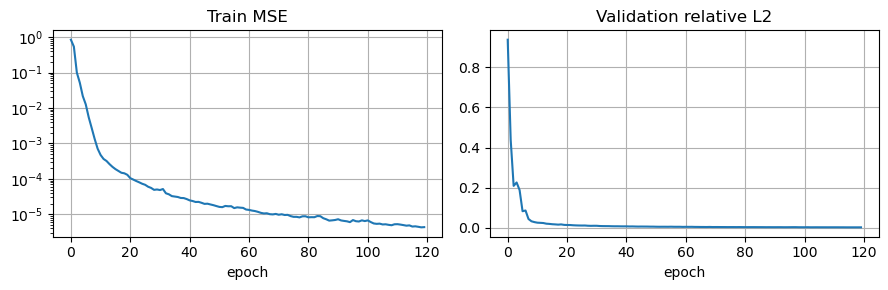

Test relative L2: mean=0.0027, median=0.0024, max=0.0083


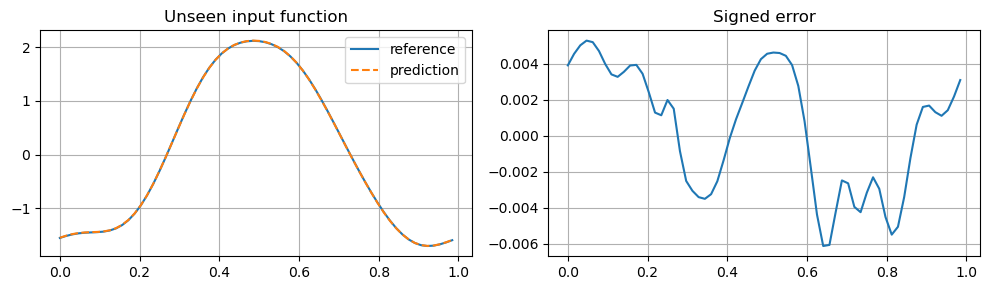

In [4]:
model = FNO1d()
history = fit(model,u0,ut,v0,vt,steps=epochs(120))
plot_history(history)
pred,error = report(model,t0,tt)
plot_1d(x,tt,pred)

## 3. 零次重新训练的跨分辨率实验

用同一批测试系数生成 128 点输入和解析参考解，网络不做任何更新。这个受控实验中函数低频且光滑；不能从成功一次推导对任意 PDE 都有超分辨率能力。提高网格密度不会自动增加学到的频率信息。

Test relative L2: mean=0.0027, median=0.0024, max=0.0083


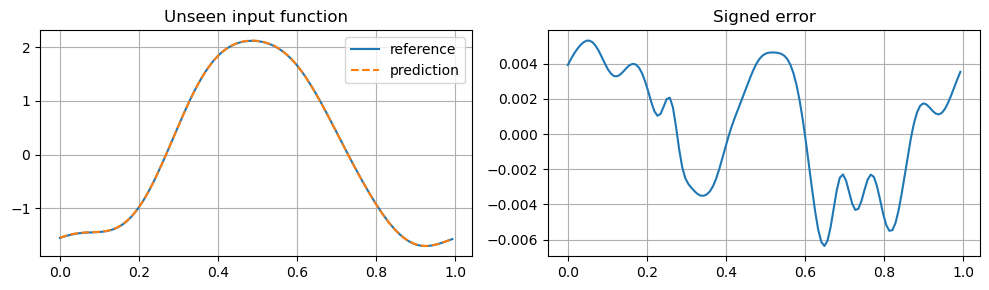

64 grid error: 0.002669532783329487 128 grid error: 0.002669528592377901
Test relative L2: mean=0.0027, median=0.0024, max=0.0083


In [5]:
xfine = torch.arange(128)/128
fine0,finet = heat_data(atest,xfine)
finepred,fineerror = report(model,fine0,finet)
plot_1d(xfine,finet,finepred)
print("64 grid error:",error.mean().item(),"128 grid error:",fineerror.mean().item())
# Also check an odd grid length, guarding the irfft(n=...) detail.
odd0,oddt = heat_data(atest,torch.arange(65)/65)
oddpred,_ = report(model,odd0,oddt)
assert oddpred.shape[-1]==65

**练习：** ① 比较 modes=3、6、10；② 改变测试 $T$ 而不训练，并解释为什么这不是网络的合法条件输入；③ 为网络加入 $\nu,T$ 通道，并在多参数数据上重新训练。

**自检：** 当前模型的输入输出 shape 是 $[B,N]$，内部是 $[B,C,N]$。FFT 会把最后一个维度变成 $N/2+1$，不会删除 batch 或通道维度。